# 7. Evaluación ampliada y robustez

Un resultado en un solo escenario no basta. Este capítulo evalúa el modelo original en otros conjuntos de datos y mide
cómo se comporta cuando cambian los hiperparámetros, la semilla, el ruido, el tamaño de la muestra y la distribución.
Salvo la evaluación en prueba, todo se hace dentro de la partición de entrenamiento, con los cinco pliegues externos de
la semilla 42 y los hiperparámetros finales de cada modelo. En los estudios de robustez el original se compara con los
dos benchmarks de boosting, XGBoost y LightGBM, que son los que más se le parecen y los mejores en regresión.

In [1]:
# Preparación: acceso a los resultados versionados y a las funciones que generan las
# tablas y figuras del informe.
import sys
sys.path.insert(0, '../ModeloOriginal')
from src import informe as inf

## 7.1. Conjuntos de datos adicionales

Los cuatro conjuntos se eligieron en el protocolo, **antes de ajustar ningún modelo en ellos**: dos con una variable
categórica omitida para todos los modelos (la situación para la que se diseñó BDL, que reproduce la exclusión de
`active_products`) y dos sin modificar, como control. La {ref}`Tabla 7.1 <tab-conjuntos-fuente>` dice de dónde sale
cada uno y por qué se eligió, y la {ref}`Tabla 7.2 <tab-conjuntos>`, cómo quedó tras prepararlo.

(tab-conjuntos-fuente)=
**Tabla 7.1.** Conjuntos de datos adicionales: fuente, origen de los datos, objetivo con su unidad y criterio de
elección.

| Conjunto | Fuente | Origen | Objetivo (unidad) | Por qué se eligió |
|---|---|---|---|---|
| Seguros médicos | {cite:t}`lantz2013`, `insurance.csv` | Simulado a partir de estadísticas demográficas de Estados Unidos | Costo médico facturado al año (dólares) | Se omite `smoker`, que desplaza el costo |
| Eficiencia energética | UCI n.º 242, {cite:t}`tsanas2012` | Simulación de edificios por computador | Carga de calefacción (kWh/m²) | Casi sin ruido; se omite el área de vidrio (cuatro niveles) |
| Abulón | UCI n.º 1, {cite:t}`nash1994` | Mediciones de ejemplares reales | Anillos de la concha (conteo; la edad en años es ese número más 1,5) | Control: objetivo entero, datos biológicos |
| Vivienda de California | {cite:t}`pace1997` | Censo de 1990, por grupo de manzanas censales | Valor mediano de la vivienda (cientos de miles de dólares) | Control: el más grande, datos de censo con estructura espacial |

Dos de los cuatro son simulados y dos provienen de mediciones reales; COFINFAD, el problema principal, es sintético.

(tab-conjuntos)=
**Tabla 7.2.** Conjuntos adicionales ya preparados: filas, predictores, variable omitida, proporción de la clase
positiva en entrenamiento y huella SHA-256 del archivo descargado.

In [2]:
# Tabla 7.2. Lee la ficha de cada conjunto
# (resultados/adicionales/<conjunto>/ficha.json), que escribe
# experiments/05_conjuntos_adicionales.py al descargarlo y partirlo.
inf.tabla('tabla_conjuntos')

| Conjunto | Filas | Predictores | Variable omitida | Clase positiva (entrenamiento) | Huella del archivo |
| :--- | ---: | ---: | :--- | ---: | :--- |
| Seguros médicos | 1.338 | 5 | smoker | 25,0 % | `505c1cbc2e63` |
| Eficiencia energética | 768 | 7 | X7 (área de vidrio) | 25,1 % | `499441eee279` |
| Abulón | 4.177 | 8 | — | 23,3 % | `755a6a67c5b2` |
| Vivienda de California | 20.640 | 8 | — | 25,0 % | `aea03e914281` |


En cada uno se repite el procedimiento del problema principal: 20 % de prueba, validación anidada de 5 × 3 con la
semilla 42 para los diez modelos, y la etiqueta «cuarto superior del objetivo» con el umbral estimado en entrenamiento.

(tab-adicionales)=
**Tabla 7.3.** Resultados por conjunto adicional y tarea: mejor benchmark, métrica en los pliegues externos del
benchmark y del original, puesto del original entre los diez modelos, ventaja relativa, p-valor de la *t* corregida,
resultado, métrica en prueba y número de clases latentes del modelo final.

In [3]:
# Tabla 7.3. De la tabla maestra de cada conjunto
# (resultados/adicionales/<conjunto>/experimentos.parquet): métrica por pliegue
# externo de cada modelo, mejor benchmark y prueba t corregida de Nadeau-Bengio del
# original contra él.
inf.tabla('tabla_adicionales')

**Regresión (RMSE, menor es mejor).**

| Conjunto | Mejor benchmark | Benchmark (externo) | Original (externo) | Puesto del original | Ventaja relativa | p (*t* corregida) | Resultado | Prueba: benchmark / original | $K$ del modelo final |
| :--- | :--- | ---: | ---: | ---: | ---: | ---: | :--- | ---: | ---: |
| Seguros médicos † | EBM | 11.332 ± 279 | 11.435 ± 334 | 7 de 10 | −0,90 % | 0,414 | Peor, no significativo | 11.459 / 11.630 | 1 (sin mezcla) |
| Eficiencia energética † | EBM | 2,263 ± 0,116 | 2,313 ± 0,068 | 2 de 10 | −2,18 % | 0,474 | Peor, no significativo | 2,317 / 2,301 | 1 (sin mezcla) |
| Abulón | Random Forest | 2,129 ± 0,093 | 2,168 ± 0,094 | 5 de 10 | −1,83 % | 0,286 | Peor, no significativo | 2,187 / 2,217 | 1 (sin mezcla) |
| Vivienda de California | LightGBM | 0,44258 ± 0,01121 | 0,46449 ± 0,00910 | 3 de 10 | −4,95 % | 0,002 | Peor, significativo | 0,43536 / 0,45210 | 1 (sin mezcla) |

**Clasificación (AUC, mayor es mejor).**

| Conjunto | Mejor benchmark | Benchmark (externo) | Original (externo) | Puesto del original | Ventaja relativa | p (*t* corregida) | Resultado | Prueba: benchmark / original | $K$ del modelo final |
| :--- | :--- | ---: | ---: | ---: | ---: | ---: | :--- | ---: | ---: |
| Seguros médicos † | EBM | 0,5722 ± 0,0323 | 0,5152 ± 0,0254 | 10 de 10 | −9,96 % | 0,037 | Peor, significativo | 0,5998 / 0,5659 | 1 (sin mezcla) |
| Eficiencia energética † | XGBoost | 0,9771 ± 0,0062 | 0,9733 ± 0,0099 | 4 de 10 | −0,38 % | 0,607 | Peor, no significativo | 0,9601 / 0,9629 | sin puntaje |
| Abulón | LightGBM | 0,8591 ± 0,0071 | 0,8485 ± 0,0116 | 7 de 10 | −1,24 % | 0,093 | Peor, no significativo | 0,8622 / 0,8606 | sin puntaje |
| Vivienda de California | LightGBM | 0,9680 ± 0,0038 | 0,9639 ± 0,0035 | 3 de 10 | −0,42 % | 0,017 | Peor, significativo | 0,9712 / 0,9664 | sin puntaje |

† Conjunto con una variable omitida. Externo: media ± desviación de los cinco pliegues externos. Ventaja relativa: positiva si el original es mejor. La prueba *t* corregida compara al original con el mejor benchmark del conjunto. $K$: clases latentes del modelo final. «Sin mezcla»: la búsqueda de hiperparámetros eligió `n_componentes = 1` y el modelo es un boosting de mínimos cuadrados con árboles propios. «BIC»: la búsqueda eligió la mezcla y el criterio BIC fijó el número de clases. «Sin puntaje»: en clasificación, la búsqueda eligió aprender de la etiqueta.


**Prueba consolidada entre conjuntos.** Friedman con corrección de Iman-Davenport sobre los rangos de los diez modelos
en los cinco conjuntos (los cuatro adicionales y COFINFAD), y Wilcoxon-Holm del original contra cada benchmark
({ref}`Tabla 7.4 <tab-consolidada>`). Las métricas no se promedian entre conjuntos porque sus escalas son distintas.

(tab-consolidada)=
**Tabla 7.4.** Prueba consolidada entre conjuntos de datos: Friedman con Iman-Davenport sobre los rangos de los diez
modelos, rango medio del original y menor p-valor de Wilcoxon-Holm frente a los benchmarks.

In [4]:
# Tabla 7.4. Rangos de los diez modelos por conjunto (media de los pliegues
# externos), prueba de Friedman con la corrección de Iman-Davenport y Wilcoxon del
# original contra cada benchmark con el ajuste de Holm.
inf.tabla('tabla_consolidada')

| Tarea | Conjuntos | Friedman con Iman-Davenport | p | Rango medio del original | Mejor rango medio | Menor p de Wilcoxon-Holm (original contra cada benchmark) | Menor p posible con estos conjuntos |
| :--- | ---: | ---: | ---: | :--- | :--- | ---: | ---: |
| Regresión | 5 | F = 3,60 | 0,003 | 3,60 (puesto 3 de 10) | EBM (2,80) | 0,562 | 0,062 |
| Clasificación | 5 | F = 3,21 | 0,006 | 5,80 (puesto 5 de 10) | XGBoost (2,20) | 0,562 | 0,062 |


Con tan pocos conjuntos la prueba de Wilcoxon no puede dar un p-valor menor que 0,05 (con cinco, el mínimo posible es
0,0625): la comparación por pares entre conjuntos no puede ser significativa sea cual sea el resultado, y se reporta por
transparencia.

In [5]:
# Lectura de las tablas 7.3 y 7.4 frente a la expectativa declarada en el protocolo
# (resultados/condicion4.json).
inf.texto('adicionales_texto')

**Lectura.** El protocolo declaró de antemano la expectativa: ventaja en los dos conjuntos con una variable omitida y empate en los dos de control.

**Regresión, el original frente al mejor benchmark de cada conjunto:** en Seguros médicos †, peor que EBM por un 0,90 % (p = 0,414); en Eficiencia energética †, peor que EBM por un 2,18 % (p = 0,474); en Abulón, peor que Random Forest por un 1,83 % (p = 0,286); en Vivienda de California, peor que LightGBM por un 4,95 % (p = 0,002). Con variable omitida, la ventaja esperada aparece en 0 de 2. En los controles, la diferencia con el mejor benchmark no es significativa en 1 de 2 (Abulón). En Seguros médicos, Eficiencia energética, Abulón y Vivienda de California la búsqueda de hiperparámetros eligió la variante sin mezcla para el modelo final (y en 5 de 5, 4 de 5, 5 de 5 y 5 de 5 pliegues externos, en ese orden): ahí el original es un boosting de mínimos cuadrados con árboles propios, y lo que gane o pierda no se debe a la clase latente. Que ocurra también en los conjuntos con una variable omitida dice que omitir una variable no basta: el modelo necesita que su efecto sea un desplazamiento constante e independiente de los demás predictores. Una explicación probable, que aquí no se contrastó: en Seguros médicos el efecto de fumar depende del índice de masa corporal, y en Eficiencia energética el área de vidrio omitida se deduce en parte de otra variable del conjunto. Condición 4: no se cumple (mejor en 0 de 4; peor de forma significativa en Vivienda de California).

**Clasificación, el original frente al mejor benchmark de cada conjunto:** en Seguros médicos †, peor que EBM por un 9,96 % (p = 0,037); en Eficiencia energética †, peor que XGBoost por un 0,38 % (p = 0,607); en Abulón, peor que LightGBM por un 1,24 % (p = 0,093); en Vivienda de California, peor que LightGBM por un 0,42 % (p = 0,017). Con variable omitida, la ventaja esperada aparece en 0 de 2. En los controles, la diferencia con el mejor benchmark no es significativa en 1 de 2 (Abulón). Condición 4: no se cumple (mejor en 0 de 4; peor de forma significativa en Seguros médicos, Vivienda de California).

En los conjuntos pequeños los pliegues externos tienen pocas filas y la desviación entre pliegues es grande: con cinco pliegues, la prueba *t* corregida solo detecta diferencias amplias, y un «no significativo» no es evidencia de igualdad.


## 7.2. Sensibilidad a los hiperparámetros propios

Se varía un hiperparámetro cada vez alrededor de la configuración final ({ref}`Figura 7.1 <fig-sensibilidad>` y
{ref}`Tabla 7.5 <tab-sensibilidad>`).

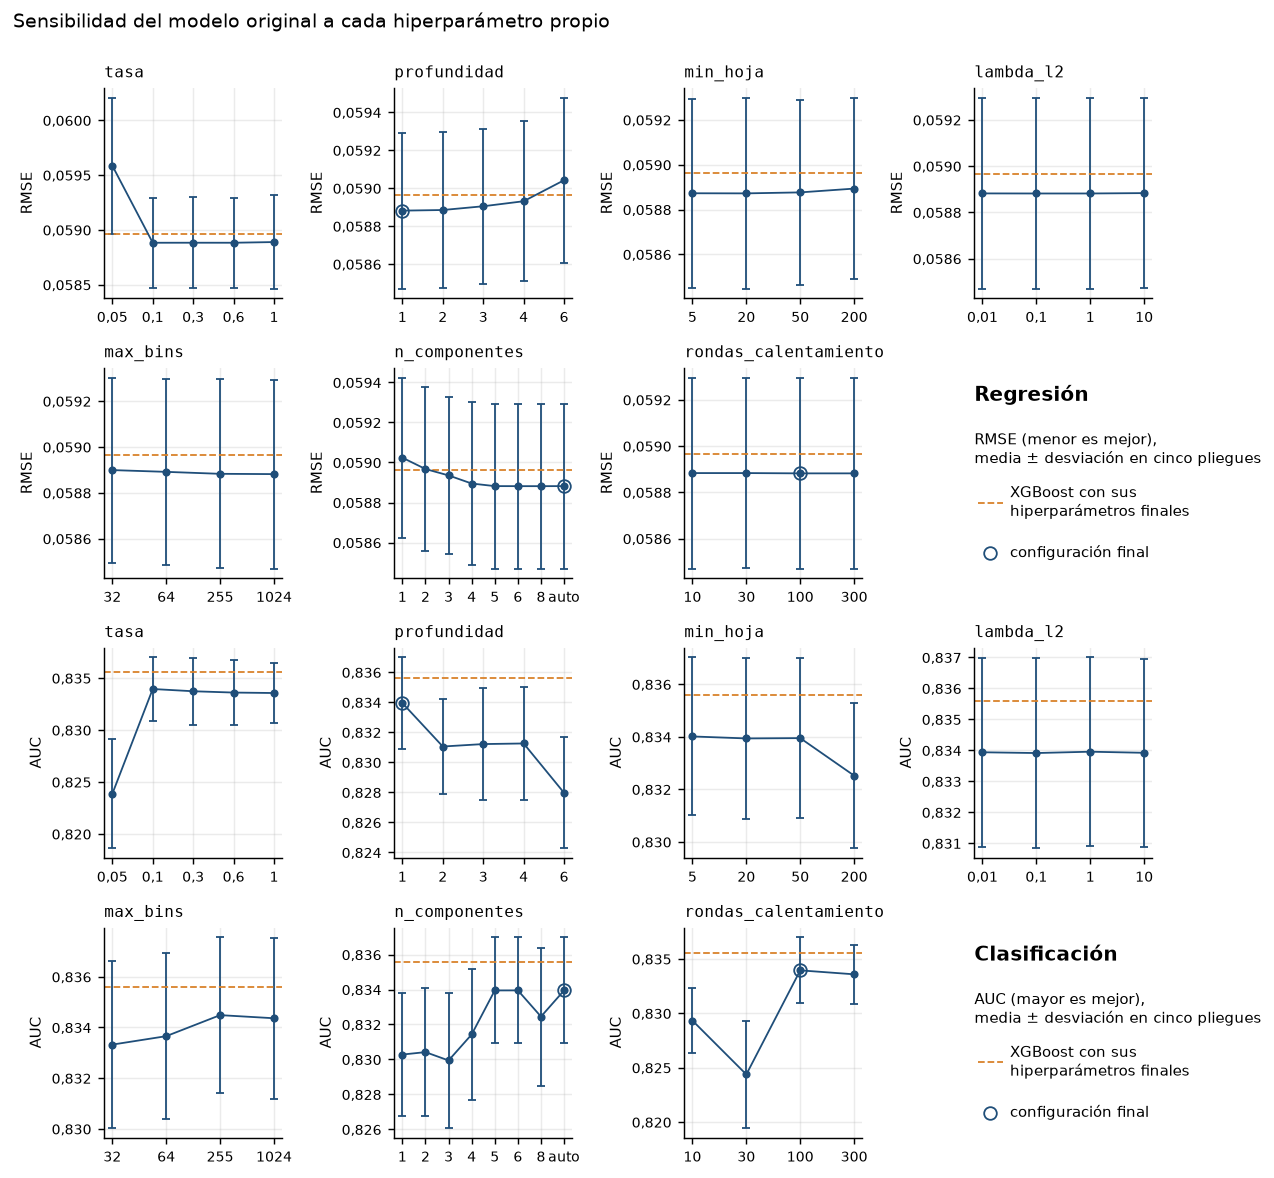

In [6]:
# Figura 7.1. Lee resultados/robustez/sensibilidad.csv (experiments/06_robustez.py
# sensibilidad): una fila por tarea, hiperparámetro y valor, con la media y la
# desviación en los cinco pliegues externos de la semilla 42.
inf.figura('sensibilidad')

(tab-sensibilidad)=
**Tabla 7.5.** Sensibilidad: número de configuraciones evaluadas, métrica de la configuración final y del mejor
benchmark con sus hiperparámetros finales, cuántas configuraciones quedan mejor que ese benchmark, y peor y mejor valor
de la métrica.

In [7]:
# Tabla 7.5. Resume sensibilidad.csv frente al mejor benchmark evaluado igual que el
# original: con sus hiperparámetros finales y en los mismos pliegues
# (resultados/robustez/muestra.csv, fila del 100 % de las filas).
inf.tabla('tabla_sensibilidad')

| Tarea | Configuraciones | Configuración final | Mejor benchmark, con sus hiperparámetros finales | Configuraciones mejores que ese benchmark | Peor valor | Mejor valor |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| Regresión | 34 | 0,05888 | 0,05896 (XGBoost) | 30 | 0,05959 | 0,05887 |
| Clasificación | 34 | 0,8339 | 0,8356 (XGBoost) | 0 | 0,8239 | 0,8345 |

Cada configuración cambia un solo hiperparámetro respecto de la final y se evalúa en los cinco pliegues externos de la semilla 42, sin nueva búsqueda. La referencia es el mejor benchmark evaluado igual: con sus hiperparámetros finales y en los mismos pliegues.

**Lectura.** En regresión, 30 de las 34 configuraciones quedan por delante de XGBoost con sus hiperparámetros finales (0,05896). La configuración final obtiene 0,05888 ± 0,00041. Pierden más de una desviación entre pliegues respecto de ella: `tasa` = 0,05. Los demás valores, y todos los de `profundidad`, `min_hoja`, `lambda_l2`, `max_bins`, `n_componentes` y `rondas_calentamiento`, quedan dentro de esa desviación. En clasificación, ninguna de las 34 configuraciones queda por delante de XGBoost con sus hiperparámetros finales (0,8356): la mejor obtiene 0,8345. La configuración final obtiene 0,8339 ± 0,0030. Pierden más de una desviación entre pliegues respecto de ella: `tasa` = 0,05; `profundidad` = 6; `n_componentes` = 1, 2 y 3; `rondas_calentamiento` = 10 y 30. Los demás valores, y todos los de `min_hoja`, `lambda_l2` y `max_bins`, quedan dentro de esa desviación. La comparación con el benchmark es homogénea: los dos modelos usan hiperparámetros finales, que se eligieron con toda la partición de entrenamiento, y por eso estas cifras son algo optimistas para ambos; la estimación del desempeño es la de la validación anidada (tablas 6.5 y 6.6). En clasificación, además, aquí el modelo original siempre usa el puntaje, mientras que en la validación anidada la búsqueda eligió no usarlo en 7 de 15 pliegues (sección 6.8).


## 7.3. Estabilidad por semilla y cómputo

Cada modelo final se reajustó con diez semillas (42 a 51) con sus hiperparámetros finales y se evaluó en prueba
({ref}`Figura 7.2 <fig-semillas>` y {ref}`Tabla 7.6 <tab-semillas>`). Esta sección mide la variación que se debe solo a
la semilla del modelo. La que se debe a la partición es la desviación entre pliegues externos de las tablas
{ref}`6.5 <tab-resumen-regresion>` y {ref}`6.6 <tab-resumen-clasificacion>`; la que se debe a la búsqueda de
hiperparámetros no se mide por separado: va dentro de esa misma desviación, porque cada pliegue externo repite la
búsqueda. Al interpretar una diferencia entre modelos hay que compararla con las tres.

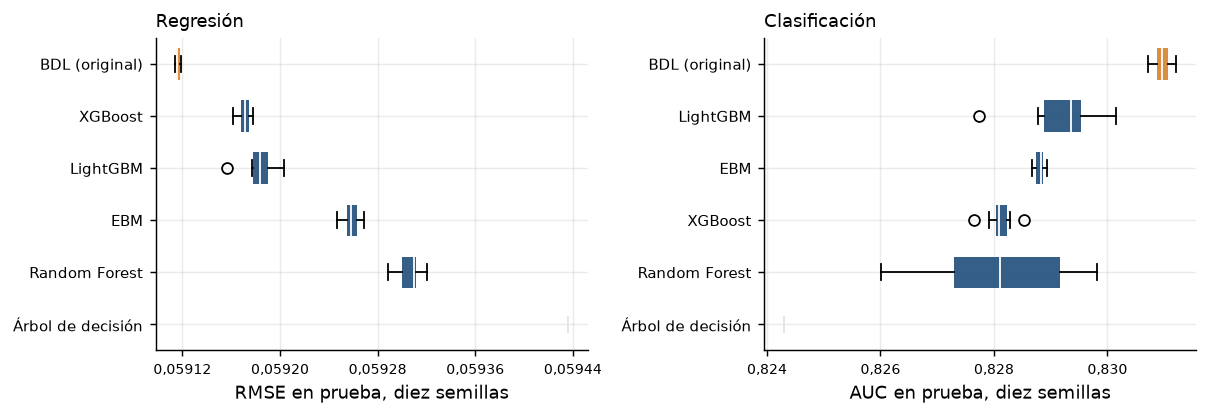

In [8]:
# Figura 7.2. Lee resultados/semillas.csv (experiments/03b_semillas.py): una fila
# por tarea, modelo y semilla.
inf.figura('semillas')

(tab-semillas)=
**Tabla 7.6.** Estabilidad por semilla y cómputo de los diez modelos de cada tarea. Primera parte: media, desviación,
intervalo de confianza del 95 % de la media, mínimo y máximo de la métrica en prueba con diez semillas. Segunda parte:
tiempo de ajuste, tiempo de inferencia sobre la prueba, memoria y tamaño del modelo serializado.

In [9]:
# Tabla 7.6. Resume semillas.csv por tarea y modelo (los modelos deterministas dan
# el mismo valor las diez veces) y añade la memoria medida en un proceso aparte por
# modelo (resultados/memoria.csv, experiments/03c_memoria.py).
inf.tabla('tabla_semillas')

**Estabilidad: métrica en prueba con diez semillas.**

| Tarea | Modelo | Media | Desviación | IC 95 % de la media | Mínimo | Máximo |
| :--- | :--- | ---: | ---: | ---: | ---: | ---: |
| Regresión | BDL (original) | 0,059116 | 0,000002 | [0,059115; 0,059118] | 0,059114 | 0,059119 |
| Regresión | XGBoost | 0,059171 | 0,000005 | [0,059168; 0,059175] | 0,059162 | 0,059178 |
| Regresión | LightGBM | 0,059183 | 0,000012 | [0,059174; 0,059192] | 0,059157 | 0,059203 |
| Regresión | EBM | 0,059259 | 0,000007 | [0,059254; 0,059263] | 0,059247 | 0,059269 |
| Regresión | Random Forest | 0,059306 | 0,000010 | [0,059299; 0,059314] | 0,059288 | 0,059321 |
| Regresión | Árbol de decisión | 0,059436 | 0,000000 | [0,059436; 0,059436] | 0,059436 | 0,059436 |
| Regresión | Lasso | 0,061661 | 0,000000 | [0,061661; 0,061661] | 0,061661 | 0,061661 |
| Regresión | Ridge | 0,061668 | 0,000000 | [0,061668; 0,061668] | 0,061668 | 0,061668 |
| Regresión | SVR lineal | 0,061703 | 0,000000 | [0,061703; 0,061703] | 0,061703 | 0,061703 |
| Regresión | k-NN | 0,063206 | 0,000000 | [0,063206; 0,063206] | 0,063206 | 0,063206 |
| Clasificación | BDL (original) | 0,83097 | 0,00014 | [0,83086; 0,83107] | 0,83072 | 0,83122 |
| Clasificación | LightGBM | 0,82919 | 0,00066 | [0,82872; 0,82966] | 0,82773 | 0,83015 |
| Clasificación | EBM | 0,82881 | 0,00009 | [0,82874; 0,82887] | 0,82867 | 0,82894 |
| Clasificación | XGBoost | 0,82811 | 0,00023 | [0,82794; 0,82827] | 0,82765 | 0,82853 |
| Clasificación | Random Forest | 0,82805 | 0,00136 | [0,82708; 0,82902] | 0,82601 | 0,82981 |
| Clasificación | Árbol de decisión | 0,82429 | 0,00000 | [0,82429; 0,82429] | 0,82429 | 0,82429 |
| Clasificación | k-NN | 0,78736 | 0,00000 | [0,78736; 0,78736] | 0,78736 | 0,78736 |
| Clasificación | Regresión logística | 0,77086 | 0,00000 | [0,77086; 0,77086] | 0,77086 | 0,77086 |
| Clasificación | SVM lineal | 0,77058 | 0,00000 | [0,77058; 0,77058] | 0,77058 | 0,77058 |
| Clasificación | Naive Bayes | 0,66625 | 0,00000 | [0,66625; 0,66625] | 0,66625 | 0,66625 |

**Cómputo de cada modelo final.**

| Tarea | Modelo | Ajuste (s) | Inferencia (s) | Memoria (MB) | Tamaño (KB) |
| :--- | :--- | ---: | ---: | ---: | ---: |
| Regresión | BDL (original) | 5,8 | 0,07 | 153 | 149 |
| Regresión | XGBoost | 1,7 | 0,06 | 154 | 58 |
| Regresión | LightGBM | 0,6 | 0,06 | 66 | 46 |
| Regresión | EBM | 25,5 | 0,05 | 81 | 1.032 |
| Regresión | Random Forest | 11,2 | 0,13 | 66 | 2.347 |
| Regresión | Árbol de decisión | 0,8 | 0,05 | 55 | 6 |
| Regresión | Lasso | 0,4 | 0,05 | 65 | 4 |
| Regresión | Ridge | 0,4 | 0,05 | 67 | 4 |
| Regresión | SVR lineal | 0,6 | 0,05 | 72 | 4 |
| Regresión | k-NN | 0,3 | 4,89 | 64 | 6.295 |
| Clasificación | BDL (original) | 11,2 | 0,15 | 158 | 90 |
| Clasificación | LightGBM | 1,2 | 0,17 | 64 | 187 |
| Clasificación | EBM | 23,4 | 0,14 | 91 | 422 |
| Clasificación | XGBoost | 1,1 | 0,13 | 162 | 193 |
| Clasificación | Random Forest | 16,2 | 0,30 | 111 | 12.992 |
| Clasificación | Árbol de decisión | 1,1 | 0,11 | 65 | 6 |
| Clasificación | k-NN | 0,2 | 9,68 | 227 | 6.208 |
| Clasificación | Regresión logística | 1,2 | 0,11 | 101 | 4 |
| Clasificación | SVM lineal | 0,8 | 0,11 | 72 | 4 |
| Clasificación | Naive Bayes | 0,3 | 0,12 | 78 | 6 |

Diez semillas (42 a 51) con los hiperparámetros finales; solo cambia la semilla del modelo, no la partición ni la búsqueda. IC 95 % de la media: con la *t* de Student sobre las diez semillas. Los modelos deterministas dan el mismo valor las diez veces. Ajuste e inferencia: media de las diez semillas; la inferencia es sobre los 9.745 clientes de prueba. Memoria: aumento máximo del conjunto de trabajo del proceso al ajustar el modelo y predecir la prueba, medido en un proceso aparte (`experiments/03c_memoria.py`). Tamaño: el modelo serializado y comprimido.


## 7.4. Ruido y valores atípicos

Se contamina la partición de entrenamiento de tres maneras (ruido en el puntaje, puntajes reemplazados por valores al
azar y ruido en los predictores numéricos) y se evalúa siempre contra datos sin contaminar
({ref}`Tabla 7.7 <tab-ruido>`).

(tab-ruido)=
**Tabla 7.7.** Métrica del original y de los dos benchmarks de boosting con distintos niveles de contaminación de los
datos de entrenamiento.

In [10]:
# Tabla 7.7. Lee resultados/robustez/ruido.csv (experiments/06_robustez.py ruido):
# media en los cinco pliegues por escenario, nivel de contaminación y modelo.
inf.tabla('tabla_ruido')

**Regresión (RMSE, menor es mejor).** El original es el mejor de los tres en 8 de 11 escenarios.

| Contaminación | Nivel | BDL (original) | XGBoost | LightGBM | Mejor |
| :--- | ---: | ---: | ---: | ---: | :--- |
| sin contaminar | 0,000 | 0,05888 | 0,05896 | 0,05899 | BDL (original) |
| ruido gaussiano en el objetivo | 0,005 | 0,05889 | 0,05896 | 0,05898 | BDL (original) |
| ruido gaussiano en el objetivo | 0,010 | 0,05890 | 0,05896 | 0,05899 | BDL (original) |
| ruido gaussiano en el objetivo | 0,020 | 0,05898 | 0,05897 | 0,05899 | XGBoost |
| ruido gaussiano en el objetivo | 0,050 | 0,05910 | 0,05901 | 0,05904 | XGBoost |
| atípicos en el objetivo | 0,010 | 0,05888 | 0,05897 | 0,05899 | BDL (original) |
| atípicos en el objetivo | 0,050 | 0,05893 | 0,05906 | 0,05908 | BDL (original) |
| atípicos en el objetivo | 0,100 | 0,05899 | 0,05923 | 0,05925 | BDL (original) |
| ruido en los predictores numéricos | 0,100 | 0,05897 | 0,05907 | 0,05907 | BDL (original) |
| ruido en los predictores numéricos | 0,250 | 0,05933 | 0,05940 | 0,05942 | BDL (original) |
| ruido en los predictores numéricos | 0,500 | 0,06157 | 0,06145 | 0,06147 | XGBoost |

**Clasificación (AUC, mayor es mejor).** El original es el mejor de los tres en 3 de 11 escenarios.

| Contaminación | Nivel | BDL (original) | XGBoost | LightGBM | Mejor |
| :--- | ---: | ---: | ---: | ---: | :--- |
| sin contaminar | 0,000 | 0,8339 | 0,8356 | 0,8325 | XGBoost |
| ruido gaussiano en el objetivo | 0,005 | 0,8302 | 0,8308 | 0,8305 | XGBoost |
| ruido gaussiano en el objetivo | 0,010 | 0,8301 | 0,8284 | 0,8297 | BDL (original) |
| ruido gaussiano en el objetivo | 0,020 | 0,8304 | 0,8260 | 0,8287 | BDL (original) |
| ruido gaussiano en el objetivo | 0,050 | 0,8297 | 0,8225 | 0,8262 | BDL (original) |
| atípicos en el objetivo | 0,010 | 0,8323 | 0,8354 | 0,8330 | XGBoost |
| atípicos en el objetivo | 0,050 | 0,8305 | 0,8348 | 0,8323 | XGBoost |
| atípicos en el objetivo | 0,100 | 0,8311 | 0,8331 | 0,8317 | XGBoost |
| ruido en los predictores numéricos | 0,100 | 0,8257 | 0,8310 | 0,8286 | XGBoost |
| ruido en los predictores numéricos | 0,250 | 0,8197 | 0,8180 | 0,8208 | LightGBM |
| ruido en los predictores numéricos | 0,500 | 0,7768 | 0,7802 | 0,7821 | LightGBM |

Nivel: desviación del ruido añadido al puntaje de entrenamiento; fracción de puntajes de entrenamiento reemplazados por un valor al azar; o desviación del ruido en los predictores numéricos, en desviaciones típicas de cada uno. La evaluación siempre es contra el puntaje y la etiqueta sin contaminar.

**Lectura.** En regresión, el original, con ruido gaussiano en el objetivo, es el mejor con 0,005 y 0,010 y no con 0,020 y 0,050 (en el nivel más alto, 0,05910 frente a 0,05901 de XGBoost); con atípicos en el objetivo, es el mejor de los tres en los 3 niveles (en el nivel más alto, 0,05899 frente a 0,05923 de XGBoost); con ruido en los predictores numéricos, es el mejor con 0,100 y 0,250 y no con 0,500 (en el nivel más alto, 0,06157 frente a 0,06145 de XGBoost). En clasificación, el original, con ruido gaussiano en el objetivo, es el mejor con 0,010, 0,020 y 0,050 y no con 0,005 (en el nivel más alto, 0,8297 frente a 0,8262 de LightGBM); con atípicos en el objetivo, no es el mejor en ninguno de los 3 niveles (en el nivel más alto, 0,8311 frente a 0,8331 de XGBoost); con ruido en los predictores numéricos, no es el mejor en ninguno de los 3 niveles (en el nivel más alto, 0,7768 frente a 0,7821 de LightGBM). En 19 de los 22 escenarios de las dos tareas la diferencia entre el original y el mejor de los otros dos es menor que la desviación del original entre pliegues; la supera a favor del original en 0 y en contra en 3 (atípicos en el objetivo de 0,050 en clasificación, ruido en los predictores numéricos de 0,100 en clasificación y ruido en los predictores numéricos de 0,500 en clasificación). El estudio muestra que una contaminación moderada no rompe al modelo, no que sea más robusto que los benchmarks. En regresión la ventaja se pierde cuando el ruido en el puntaje llega a 0,020: los niveles del escalón están separados 0,05, y la Proposición 4 solo promete ganancia mientras esa separación sea grande frente al ruido.


## 7.5. Tamaño de muestra y escalabilidad

La {ref}`Figura 7.3 <fig-aprendizaje>` y la {ref}`Tabla 7.8 <tab-muestra>` muestran la curva de aprendizaje y el tiempo
de ajuste al variar el número de filas; la {ref}`Tabla 7.9 <tab-columnas>`, el tiempo de ajuste al variar el número de
columnas y el de inferencia al variar el número de filas.

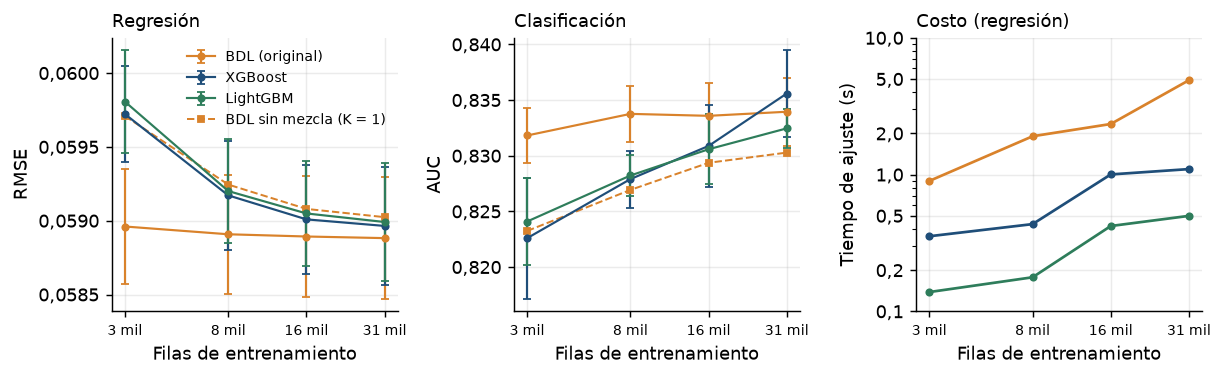

In [11]:
# Figura 7.3. Lee resultados/robustez/muestra.csv y muestra_sin_mezcla.csv
# (experiments/06_robustez.py muestra mezcla): las filas se submuestrean dentro de
# cada pliegue de entrenamiento y la evaluación usa el pliegue de prueba completo.
inf.figura('aprendizaje')

(tab-muestra)=
**Tabla 7.8.** Curva de aprendizaje: métrica (media ± desviación) de los tres modelos y del original sin la mezcla, y
tiempo de ajuste, según el número de filas de entrenamiento.

In [12]:
# Tabla 7.8. Resume muestra.csv y muestra_sin_mezcla.csv: con cuántas filas alcanza
# el original el valor del mejor de los otros dos, y qué parte de esa ventaja
# desaparece al retirar la mezcla.
inf.tabla('tabla_muestra')

**Métrica: RMSE en regresión y AUC en clasificación.**

| Tarea | Filas | BDL (original) | XGBoost | LightGBM | BDL sin mezcla (K = 1) |
| :--- | ---: | ---: | ---: | ---: | ---: |
| Regresión | 3.118 | 0,05896 ± 0,00039 | 0,05972 ± 0,00032 | 0,05981 ± 0,00035 | 0,05971 ± 0,00035 |
| Regresión | 7.796 | 0,05891 ± 0,00040 | 0,05917 ± 0,00037 | 0,05920 ± 0,00035 | 0,05924 ± 0,00035 |
| Regresión | 15.591 | 0,05889 ± 0,00041 | 0,05901 ± 0,00037 | 0,05905 ± 0,00035 | 0,05908 ± 0,00035 |
| Regresión | 31.182 | 0,05888 ± 0,00041 | 0,05896 ± 0,00040 | 0,05899 ± 0,00040 | 0,05902 ± 0,00040 |
| Clasificación | 3.118 | 0,8318 ± 0,0025 | 0,8226 ± 0,0055 | 0,8241 ± 0,0039 | 0,8232 ± 0,0034 |
| Clasificación | 7.796 | 0,8338 ± 0,0025 | 0,8279 ± 0,0026 | 0,8282 ± 0,0019 | 0,8269 ± 0,0047 |
| Clasificación | 15.591 | 0,8336 ± 0,0030 | 0,8309 ± 0,0037 | 0,8306 ± 0,0032 | 0,8294 ± 0,0032 |
| Clasificación | 31.182 | 0,8339 ± 0,0030 | 0,8356 ± 0,0039 | 0,8325 ± 0,0018 | 0,8303 ± 0,0035 |

**Tiempo de ajuste, en segundos.**

| Tarea | Filas | BDL (original) | XGBoost | LightGBM |
| :--- | ---: | ---: | ---: | ---: |
| Regresión | 3.118 | 0,9 | 0,4 | 0,1 |
| Regresión | 7.796 | 1,9 | 0,4 | 0,2 |
| Regresión | 15.591 | 2,3 | 1,0 | 0,4 |
| Regresión | 31.182 | 4,9 | 1,1 | 0,5 |
| Clasificación | 3.118 | 1,5 | 0,4 | 0,5 |
| Clasificación | 7.796 | 2,6 | 0,4 | 0,3 |
| Clasificación | 15.591 | 4,6 | 0,5 | 0,5 |
| Clasificación | 31.182 | 8,5 | 0,8 | 1,2 |

Media ± desviación en los cinco pliegues externos de la semilla 42, con los hiperparámetros finales; las filas se submuestrean dentro de cada pliegue de entrenamiento y la evaluación usa el pliegue de prueba completo. Ningún modelo se reajusta para cada tamaño: parte de la diferencia con pocas filas puede deberse a que los hiperparámetros se eligieron con todas.

**Regresión.** Con 3.118 filas (el 10 %), el original obtiene 0,05896 y XGBoost, 0,05972; con las 31.182, 0,05888 y 0,05896. El original alcanza con 3.118 filas el valor que XGBoost obtiene con todas: la ventaja del modelo es de eficiencia muestral y se reduce al crecer la muestra, cuando todos se acercan al límite.

**Clasificación.** Con 3.118 filas (el 10 %), el original obtiene 0,8318 y XGBoost, 0,8226; con las 31.182, 0,8339 y 0,8356. Con todas las filas, XGBoost queda por delante: la ventaja del original aparece con muestras pequeñas y desaparece al crecer la muestra.

**Qué parte se debe a la mezcla.** La misma curva para el modelo original con $K = 1$ (línea discontinua): en regresión, con 3.118 filas el modelo completo obtiene 0,05896; sin la mezcla, 0,05971, y XGBoost, 0,05972 (con las 31.182, la variante sin mezcla llega a 0,05902, que el modelo completo ya supera con 3.118); en clasificación, con 3.118 filas el modelo completo obtiene 0,8318; sin la mezcla, 0,8232, y LightGBM, 0,8241 (con las 31.182, la variante sin mezcla llega a 0,8303, que el modelo completo ya supera con 3.118). Sin la clase latente, el modelo se comporta como los benchmarks: la ventaja con pocas filas la da la mezcla, que es lo que predice la Proposición 4. La variante usa aquí los hiperparámetros del modelo completo; en la ablación de la sección 5.9, donde tiene su propia búsqueda, la diferencia con todas las filas es de 0,000107 de RMSE y 0,00211 de AUC. Este análisis se añadió después de ver los resultados y es exploratorio (sección 6.2).

**Costo.** Al multiplicar las filas por 10, el tiempo de ajuste del original se multiplica por 5,5 (el de XGBoost, por 3,1): crece como mucho de forma lineal, como predice la sección 5.7. Con todas las filas el original tarda 4,5 veces lo que XGBoost.


(tab-columnas)=
**Tabla 7.9.** Escalabilidad. Primera parte: tiempo de ajuste al variar el número de columnas originales, con las
mismas filas. Segunda parte: tiempo de inferencia del modelo original y del mejor benchmark de regresión al variar el
número de filas.

In [13]:
# Tabla 7.9. Lee resultados/robustez/columnas.csv (tiempo de ajuste con las primeras
# 6, 12, 24 y 48 columnas) y resultados/inferencia_filas.csv
# (experiments/03c_memoria.py: mediana de cinco medidas con 1.000, 10.000 y 100.000
# filas).
inf.tabla('tabla_columnas', 'tabla_inferencia')

| Columnas originales | Ajuste BDL (original) (s) | Ajuste XGBoost (s) |
| ---: | ---: | ---: |
| 6 | 0,9 | 0,8 |
| 12 | 1,0 | 0,9 |
| 24 | 2,7 | 1,0 |
| 48 | 4,3 | 2,7 |

Al multiplicar las columnas por 8, el tiempo del original se multiplica por 4,9 y el de XGBoost, por 3,4.


| Filas | Inferencia BDL (original) (s) | Inferencia XGBoost (s) | BDL (original): microsegundos por fila | XGBoost: microsegundos por fila |
| ---: | ---: | ---: | ---: | ---: |
| 1.000 | 0,014 | 0,012 | 14,1 | 12,0 |
| 10.000 | 0,064 | 0,062 | 6,4 | 6,2 |
| 100.000 | 0,623 | 0,585 | 6,2 | 5,9 |

Mediana de cinco medidas; la tubería incluye el preprocesamiento. Al multiplicar las filas por 100, el tiempo de inferencia del original se multiplica por 44,2: crece de forma lineal o menos, como predice la sección 5.7.


La complejidad de la sección 5.7 predice un costo de ajuste lineal en $n$ y en $p$ y un costo de inferencia lineal en
$n$; las tablas {ref}`7.8 <tab-muestra>` y {ref}`7.9 <tab-columnas>` lo contrastan con el tiempo medido.

## 7.6. Cambio de distribución

Se deja fuera una ciudad cada vez: los modelos se ajustan con los clientes de las demás y se evalúan en la que quedó
fuera ({ref}`Tabla 7.10 <tab-ciudades>`). Los hiperparámetros son los finales, que se eligieron con clientes de todas las
ciudades: la ciudad excluida no interviene en el ajuste, pero sí intervino en esa elección.

(tab-ciudades)=
**Tabla 7.10.** Cambio de distribución espacial: métrica de los tres modelos en la ciudad que se deja fuera.

In [14]:
# Tabla 7.10. Lee resultados/robustez/ciudades.csv (experiments/06_robustez.py
# ciudades): una fila por tarea, ciudad excluida y modelo.
inf.tabla('tabla_ciudades')

**Regresión (RMSE, menor es mejor).** El original es el mejor de los tres en 16 de 18 ciudades.

| Ciudad que se deja fuera | Clientes | BDL (original) | XGBoost | LightGBM |
| :--- | ---: | ---: | ---: | ---: |
| Armenia, Quindío | 405 | 0,06048 | 0,06048 | 0,06060 |
| Barranquilla, Atlántico | 3.069 | 0,05873 | 0,05879 | 0,05887 |
| Bogotá, Cundinamarca | 13.613 | 0,05944 | 0,05950 | 0,05950 |
| Bucaramanga, Santander | 1.512 | 0,05897 | 0,05913 | 0,05907 |
| Cali, Valle del Cauca | 4.669 | 0,05817 | 0,05825 | 0,05827 |
| Cartagena, Bolívar | 1.898 | 0,05878 | 0,05888 | 0,05887 |
| Cúcuta, Norte de Santander | 1.556 | 0,05879 | 0,05890 | 0,05896 |
| Ibagué, Tolima | 849 | 0,05793 | 0,05819 | 0,05819 |
| Manizales, Caldas | 782 | 0,05883 | 0,05891 | 0,05902 |
| Medellín, Antioquia | 5.909 | 0,05895 | 0,05908 | 0,05909 |
| Montería, Córdoba | 172 | 0,05396 | 0,05413 | 0,05423 |
| Neiva, Huila | 395 | 0,06065 | 0,06075 | 0,06067 |
| Pasto, Nariño | 786 | 0,05862 | 0,05876 | 0,05879 |
| Pereira, Risaralda | 1.131 | 0,05810 | 0,05824 | 0,05822 |
| Santa Marta, Magdalena | 1.243 | 0,05730 | 0,05732 | 0,05738 |
| Sincelejo, Sucre | 175 | 0,06123 | 0,06116 | 0,06123 |
| Valledupar, Cesar | 406 | 0,05780 | 0,05788 | 0,05782 |
| Villavicencio, Meta | 408 | 0,05751 | 0,05751 | 0,05755 |
| **Media** | — | **0,05857** | **0,05866** | **0,05869** |

**Clasificación (AUC, mayor es mejor).** El original es el mejor de los tres en 6 de 18 ciudades.

| Ciudad que se deja fuera | Clientes | BDL (original) | XGBoost | LightGBM |
| :--- | ---: | ---: | ---: | ---: |
| Armenia, Quindío | 405 | 0,8572 | 0,8571 | 0,8483 |
| Barranquilla, Atlántico | 3.069 | 0,8236 | 0,8191 | 0,8170 |
| Bogotá, Cundinamarca | 13.613 | 0,8345 | 0,8342 | 0,8376 |
| Bucaramanga, Santander | 1.512 | 0,8312 | 0,8398 | 0,8287 |
| Cali, Valle del Cauca | 4.669 | 0,8443 | 0,8482 | 0,8418 |
| Cartagena, Bolívar | 1.898 | 0,8245 | 0,8253 | 0,8141 |
| Cúcuta, Norte de Santander | 1.556 | 0,8256 | 0,8283 | 0,8282 |
| Ibagué, Tolima | 849 | 0,8434 | 0,8516 | 0,8465 |
| Manizales, Caldas | 782 | 0,8331 | 0,8457 | 0,8515 |
| Medellín, Antioquia | 5.909 | 0,8301 | 0,8318 | 0,8283 |
| Montería, Córdoba | 172 | 0,8453 | 0,8505 | 0,8522 |
| Neiva, Huila | 395 | 0,7898 | 0,7861 | 0,7691 |
| Pasto, Nariño | 786 | 0,8443 | 0,8387 | 0,8339 |
| Pereira, Risaralda | 1.131 | 0,8477 | 0,8399 | 0,8423 |
| Santa Marta, Magdalena | 1.243 | 0,8328 | 0,8330 | 0,8238 |
| Sincelejo, Sucre | 175 | 0,8413 | 0,8471 | 0,8447 |
| Valledupar, Cesar | 406 | 0,8412 | 0,8262 | 0,8139 |
| Villavicencio, Meta | 408 | 0,8291 | 0,8257 | 0,8399 |
| **Media** | — | **0,8344** | **0,8349** | **0,8312** |

**Lectura.** En regresión, la media simple de las 18 ciudades es 0,05857 para el original y 0,05866 para XGBoost; con pliegues al azar y la misma configuración, el original obtiene 0,05888 ± 0,00041: evaluar en una ciudad que no se vio no empeora su resultado. En clasificación, la media simple de las 18 ciudades es 0,8344 para el original y 0,8349 para XGBoost; con pliegues al azar y la misma configuración, el original obtiene 0,8339 ± 0,0030: evaluar en una ciudad que no se vio no empeora su resultado. Las ciudades pequeñas pesan lo mismo que las grandes en esa media, y en las de pocos cientos de clientes (6 de 18 tienen menos de 500) las diferencias entre modelos son ruido de muestreo. Como dejar fuera una ciudad no degrada a ninguno de los tres modelos, en COFINFAD la relación entre los predictores y el puntaje no parece cambiar de una ciudad a otra: este estudio no es una prueba exigente de cambio de distribución.


## 7.7. Calibración y reglas de puntuación

La {ref}`Tabla 7.11 <tab-calibracion>` reporta las reglas de puntuación propias de los diez clasificadores y la
{ref}`Figura 7.4 <fig-calibracion>`, la curva de calibración del original frente al mejor benchmark.

(tab-calibracion)=
**Tabla 7.11.** Clasificación en prueba: AUC, precisión media, captura de la campaña del 25 %, pérdida logarítmica,
puntaje de Brier y error de calibración esperado (ECE), tal como sale cada modelo y tras recalibrarlo.

In [15]:
# Tabla 7.11. Lee resultados/metricas_prueba.csv (experiments/03_prueba.py). La
# recalibración isotónica de cada modelo se ajusta con sus predicciones fuera de
# pliegue de entrenamiento, nunca con la prueba.
inf.tabla('tabla_calibracion')

| Modelo | AUC | Precisión media | Captura al 25 % | Pérdida log. | Brier | ECE | Pérdida log. (isotónica) | Brier (isotónica) | ECE (isotónica) |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| **BDL (original)** | 0,8311 | 0,5103 | 51,4 % | 0,3688 | 0,1301 | 0,0081 | 0,3683 | 0,1301 | 0,0067 |
| LightGBM | 0,8296 | 0,5535 | 51,0 % | 0,4571 | 0,1667 | 0,1488 | 0,3698 | 0,1315 | 0,0219 |
| EBM | 0,8289 | 0,5512 | 51,2 % | 0,5214 | 0,1732 | 0,1698 | 0,3863 | 0,1338 | 0,0050 |
| XGBoost | 0,8283 | 0,5480 | 51,0 % | 0,5621 | 0,1875 | 0,2161 | 0,3675 | 0,1305 | 0,0066 |
| Random Forest | 0,8260 | 0,5444 | 49,4 % | 0,3735 | 0,1323 | 0,0211 | 0,3676 | 0,1307 | 0,0107 |
| Árbol de decisión | 0,8243 | 0,5304 | 49,5 % | 0,4524 | 0,1690 | 0,1442 | 0,3678 | 0,1308 | 0,0111 |
| k-NN | 0,7874 | 0,5017 | 50,8 % | 0,5045 | 0,1660 | 0,1079 | 0,4549 | 0,1510 | 0,0077 |
| Regresión logística | 0,7709 | 0,5079 | 51,1 % | 0,5747 | 0,1977 | 0,1993 | 0,4586 | 0,1521 | 0,0053 |
| SVM lineal | 0,7706 | 0,5067 | 51,1 % | — | — | — | 0,4624 | 0,1523 | 0,0072 |
| Naive Bayes | 0,6662 | 0,3627 | 40,8 % | 3,2131 | 0,6600 | 0,6647 | 0,5250 | 0,1736 | 0,0072 |

ECE: error de calibración esperado con diez tramos de igual número de clientes; el dashboard lo calcula con diez tramos de igual ancho, como el Entregable 3, y por eso sus cifras no coinciden exactamente con las de esta tabla. Isotónica: recalibración ajustada con las predicciones fuera de pliegue de entrenamiento. El SVM lineal no da probabilidades: solo se reporta recalibrado.

**Dos columnas dependen de los empates.** La probabilidad del original toma 219 valores distintos, y 4.354 clientes comparten la del corte de la campaña (Tabla 6.11). Su captura al 25 % es la del desempate del protocolo; con un desempate al azar se espera 51,3 % ± 0,6 puntos. Su precisión media es la de la convención de scikit-learn, que cuenta a los empatados como un solo punto; con los empates rotos al azar es 0,5507 ± 0,0046.


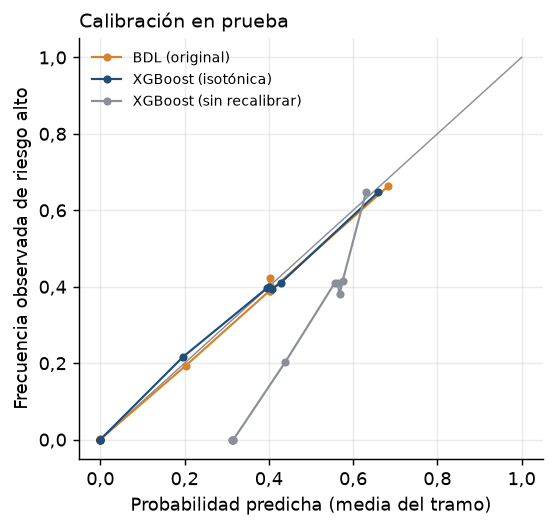

In [16]:
# Figura 7.4. De resultados/predicciones_prueba.parquet: el original, y el mejor
# benchmark antes y después de recalibrar.
inf.figura('calibracion')

## 7.8. Cuantificación de la incertidumbre

La {ref}`Tabla 7.12 <tab-incertidumbre>` compara la cobertura medida y el largo de los intervalos y de los conjuntos de
predicción, y la {ref}`Figura 7.5 <fig-predictiva>` muestra la distribución predictiva de un cliente.

(tab-incertidumbre)=
**Tabla 7.12.** Regresión en prueba: cobertura medida y largo de los intervalos y de los conjuntos de predicción, para
tres coberturas nominales.

In [17]:
# Tabla 7.12. Lee resultados/incertidumbre_prueba.csv: intervalo conforme del mejor
# benchmark (pronóstico ± q, con q de sus errores fuera de pliegue), y los
# intervalos y conjuntos de predicción del modelo original.
inf.tabla('tabla_incertidumbre')

| Cobertura nominal | Método | Cobertura en prueba | Largo | Tramos |
| :--- | :--- | ---: | ---: | ---: |
| 80 % | XGBoost: intervalo conforme | 80,5 % | 0,1161 | — |
| 80 % | XGBoost: conjunto por densidad de sus residuos (exploratorio) | 82,2 % | 0,0301 | 4 |
| 80 % | BDL: intervalo conforme con la misma receta | 84,4 % | 0,1101 | — |
| 80 % | BDL: intervalo central | 80,5 % | 0,1500 | — |
| 80 % | BDL: conjunto de predicción | 79,8 % | 0,0040 | 3 |
| 90 % | XGBoost: intervalo conforme | 90,0 % | 0,1905 | — |
| 90 % | XGBoost: conjunto por densidad de sus residuos (exploratorio) | 91,6 % | 0,0436 | 5 |
| 90 % | BDL: intervalo conforme con la misma receta | 84,7 % | 0,1903 | — |
| 90 % | BDL: intervalo central | 89,9 % | 0,1502 | — |
| 90 % | BDL: conjunto de predicción | 89,9 % | 0,0062 | 4 |
| 95 % | XGBoost: intervalo conforme | 95,1 % | 0,2375 | — |
| 95 % | XGBoost: conjunto por densidad de sus residuos (exploratorio) | 95,9 % | 0,0550 | 5 |
| 95 % | BDL: intervalo conforme con la misma receta | 95,0 % | 0,2311 | — |
| 95 % | BDL: intervalo central | 95,4 % | 0,2001 | — |
| 95 % | BDL: conjunto de predicción | 95,0 % | 0,0099 | 5 |

Al 90 %, el conjunto de predicción del modelo original mide 0,0062 y el intervalo del mejor benchmark, 0,1905: **31 veces más corto** con la misma cobertura nominal. Con 9.745 clientes de prueba, el error de muestreo de una cobertura del 90 % es de ±0,6 puntos.

**La receta «pronóstico ± q» no sirve para el modelo original.** Su cobertura medida fue 84,4 % para el 80 % nominal y 84,7 % para el 90 % nominal. La causa no está en el modelo sino en la receta: cuando el error tiene escalones, el cuantil *q* cae justo sobre uno de ellos, y que ese nivel entero quede dentro o fuera del intervalo depende de diferencias de diezmilésimas entre el modelo final y los modelos de los pliegues con los que se calculó *q*. En los benchmarks no se nota porque su propio error difumina los escalones. Los conjuntos de predicción del modelo no tienen ese problema: se construyen con la densidad del error, no con una distancia al pronóstico.

**Con la misma receta para los dos.** El conjunto del original es un conjunto por densidad y el intervalo del benchmark es simétrico, así que parte de la diferencia es de receta. Una mezcla ajustada a los residuos fuera de pliegue de XGBoost también encuentra 5 niveles, y el conjunto por densidad que resulta mide 0,0436 al 90 % (cobertura en prueba: 91,6 %). Frente a esa referencia, el conjunto del original es 7 veces más corto: esa es la parte atribuible a que estima mejor el índice. Es una comparación exploratoria, añadida después de ver los resultados (`experiments/04e_referencias_homogeneas.py`).


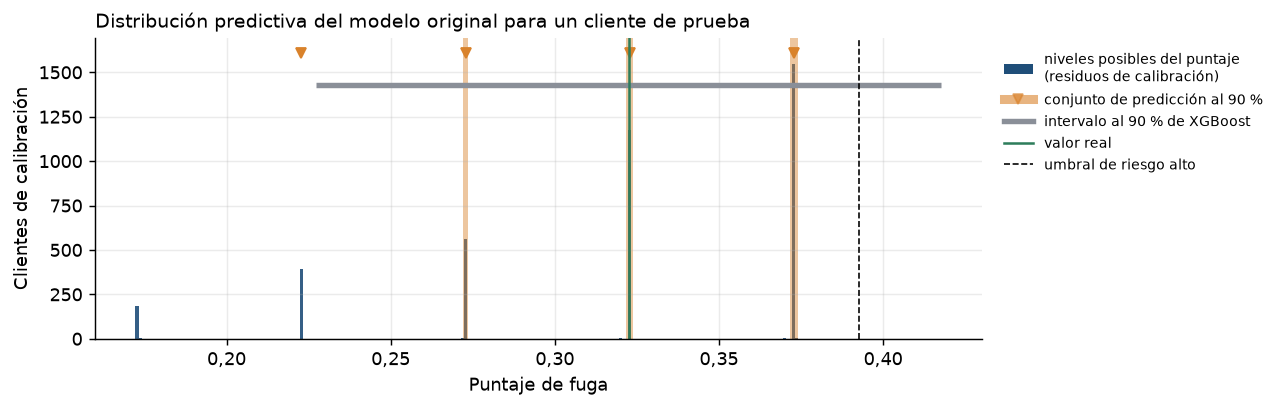

In [18]:
# Figura 7.5. Para el primer cliente de prueba: índice del modelo más sus residuos
# de calibración (la distribución predictiva), tramos del conjunto al 90 %
# (conjunto_residual) e intervalo del mejor benchmark.
inf.figura('distribucion_predictiva')

## 7.9. Análisis de errores

La {ref}`Tabla 7.13 <tab-errores>` compara al original con el mejor benchmark de cada tarea por subgrupos de clientes
de prueba.

(tab-errores)=
**Tabla 7.13.** Error por subgrupo de prueba: RMSE y AUC del original y del mejor benchmark de cada tarea, y cuál es
mejor en cada subgrupo.

In [19]:
# Tabla 7.13. De predicciones_prueba.parquet: RMSE y AUC por edad, por la cola de
# tx_count y por segmento de cliente.
inf.tabla('tabla_errores')

| Subgrupo de prueba | Clientes | RMSE original | RMSE XGBoost | Mejor | AUC original | AUC XGBoost | Mejor |
| :--- | ---: | ---: | ---: | :--- | ---: | ---: | :--- |
| Todos | 9.745 | 0,05912 | 0,05917 | original | 0,8311 | 0,8283 | original |
| Edad 29 | 1.643 | 0,05928 | 0,05942 | original | 0,8252 | 0,8269 | benchmark |
| Edad 30 | 1.581 | 0,06012 | 0,06010 | benchmark | 0,8497 | 0,8537 | benchmark |
| Edad 44 | 1.598 | 0,05843 | 0,05853 | original | 0,9183 | 0,9153 | original |
| Edad 45 | 1.576 | 0,05830 | 0,05830 | benchmark | 0,9384 | 0,9448 | benchmark |
| Edad 59 | 1.631 | 0,05858 | 0,05869 | original | 0,6171 | 0,6172 | benchmark |
| Edad 60 | 1.716 | 0,05989 | 0,05993 | original | 0,6675 | 0,6595 | original |
| tx_count > 500 (cola) | 134 | 0,06306 | 0,06344 | original | 0,8117 | 0,8531 | benchmark |
| tx_count ≤ 500 | 9.611 | 0,05906 | 0,05911 | original | 0,8309 | 0,8275 | original |
| Segmento inactive | 1.954 | 0,05874 | 0,05875 | original | 0,8275 | 0,8333 | benchmark |
| Segmento occasional | 3.852 | 0,05870 | 0,05877 | original | 0,8342 | 0,8268 | original |
| Segmento power | 1.026 | 0,05885 | 0,05894 | original | 0,8272 | 0,8195 | original |
| Segmento regular | 2.913 | 0,06000 | 0,06006 | original | 0,8309 | 0,8308 | original |


In [20]:
# Dónde falla el modelo y por qué: descompone el error con active_products (solo
# para el análisis) y con las probabilidades de prueba.
inf.texto('errores_texto')

**El error de regresión es casi todo escalón.** Con `active_products` (que el modelo nunca ve) se puede reconstruir el índice real de cada cliente de prueba y compararlo con el que estima el modelo: la desviación de esa diferencia es 0,00130, frente a un RMSE total de 0,05912. Más del 99,9 % del error cuadrático es el escalón, que ningún modelo puede predecir sin la variable excluida.

**Los errores grandes son los clientes con muchos productos.** Predecir la media obliga a equivocarse más con los niveles poco frecuentes: los clientes con 5 productos son el 4,9 % de la prueba y aportan el 29,9 % del error cuadrático (RMSE de 0,1454 en ese grupo). La cobertura de los conjuntos de predicción es del total de clientes, no de cada grupo: como ese es el nivel menos probable, es el que queda fuera. Al 90 % el conjunto cubre al 0,0 % de esos clientes; al 95 %, al 10,0 %, y al 99 %, al 91,3 %. Quien necesite cubrir a los clientes con muchos productos tiene que pedir una cobertura alta.

**La cola de `tx_count`.** En los 134 clientes de prueba con más de 500 transacciones (1,4 %) el índice depende además de esa variable. Ahí el RMSE del original sube a 0,06306 y su AUC es 0,8117, frente a 0,8531 de XGBoost: es el subgrupo donde el original pierde con más claridad. Hay pocos clientes para aprender ese efecto, y el modelo lo confunde en parte con un cambio de nivel.

**H4 no se cumple, y la diferencia está en 2 clientes.** La probabilidad del original tiene mesetas: vale casi 0 cuando ningún nivel del escalón deja al cliente por encima del umbral, y salta al entrar el primero. Si el índice estimado queda una milésima por debajo del real justo en ese borde, el modelo dice «casi imposible» y se equivoca. En prueba pasó con 2 de 9.745 clientes, que aportan 0,0018 de los 0,3688 de pérdida logarítmica del original. Sin esos clientes, y quitándoselos a los dos modelos, la pérdida del original es 0,3670 y la de XGBoost recalibrado, 0,3674: un empate. Es el precio de una probabilidad tan nítida: la dispersión robusta con la que se calcula la excedencia hace los bordes muy abruptos. Una dispersión mayor suavizaría los bordes; no se cambió porque el protocolo ya estaba registrado. Este desglose se hizo después de ver los resultados.

**Por subgrupos**, el original tiene menor RMSE que el mejor benchmark en 10 de 12 y mayor AUC en 6 de 12. Las diferencias dentro de cada subgrupo son del mismo orden que en el total y cambian de signo de uno a otro: no hay un grupo de clientes al que el modelo sirva claramente peor, salvo la cola de `tx_count`.
